# QAOA



In [20]:
import pennylane as qp
import pennylane.numpy as np
import networkx as nx
import matplotlib.pyplot as plt

np.random.seed(42)

#### The MaxCut Problem:
We have  a graph $G=(V,E)$ with nodes in $V$ and edges in $E$. The cost of the maxcut will be: $C(z)=\sum_{(i,j)\in E}\frac{1-z_i z_j}{2},\qquad z_i\in\{-1,+1\}.$

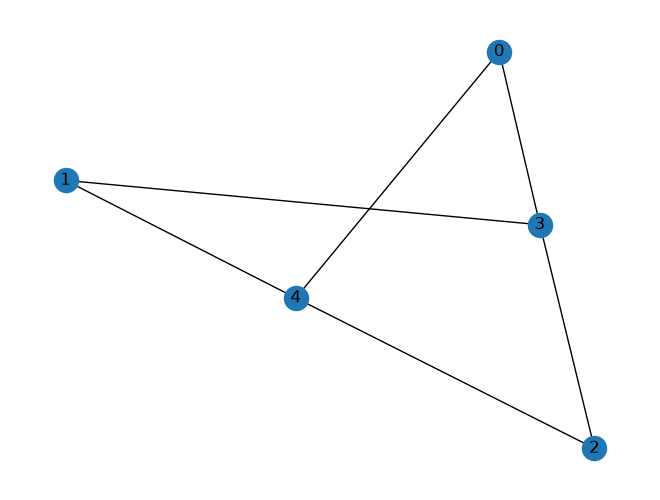

In [21]:
G = nx.Graph()
G.add_edges_from([[0, 3], [0, 4], [1, 3], [1, 4], [2, 3], [2, 4]])
nx.draw(G,with_labels=True)

####  Mapping
The mapping to the Ising Model turns out to be: 
$C=\sum_{(i,j)\in E}\frac{1-Z_i Z_j}{2},$


Now let's look at the QAOA operators:

$$
U_C(\gamma)
=
e^{-i\gamma C}
=
\prod_{(i,j)\in E}
e^{-i\frac{\gamma}{2}(I-Z_iZ_j)}.
$$
The mixer Hamiltonian is
$H_M=\sum_{i=1}^{n}X_i,$ with corresponding unitary

$$U_M(\beta)=e^{-i\beta H_M}=
\prod_{i=1}^{n}e^{-i\beta X_i}.
$$


In [25]:
n_wires = len(G.nodes())

def U_B(beta):
    for wire in range(n_wires):
        qp.RX(2*beta,wires=wire)

def U_C(gamma):
    for edge in G.edges():
        qp.CNOT(wires=edge)
        qp.RZ(gamma,wires=edge[1])
        qp.CNOT(wires=edge)


Starting from the uniform superposition $\ket{+}^{\otimes n}$, the $p$-layer QAOA state is
\begin{equation}
    \ket{\boldsymbol{\gamma},\boldsymbol{\beta}}
    = U_M(\beta_p)\,U_C(\gamma_p)\cdots U_M(\beta_1)\,U_C(\gamma_1)\,\ket{+}^{\otimes n},
\end{equation}
where the first layer acts first.
The QAOA objective is the expected cut size
\begin{equation}
    F(\boldsymbol{\gamma},\boldsymbol{\beta})
    = \bra{\boldsymbol{\gamma},\boldsymbol{\beta}}\, C \,\ket{\boldsymbol{\gamma},\boldsymbol{\beta}},
\end{equation}
and the parameters are optimized as
\begin{equation}
    (\boldsymbol{\gamma}^*,\boldsymbol{\beta}^*)
    = \operatorname*{arg\,max}_{\boldsymbol{\gamma},\boldsymbol{\beta}} \; F(\boldsymbol{\gamma},\boldsymbol{\beta}),
\end{equation}
or, equivalently, by minimizing $\langle -C \rangle$.

In [26]:
dev = qp.device("default.qubit", wires=n_wires)
N_SHOTS=1000

@qp.set_shots(N_SHOTS)
@qp.qnode(dev)
def qaoa_circuit(gammas,betas,return_samples=False):
    for wire in range(n_wires):
        qp.Hadamard(wires=wire)

    for gamma,beta in zip(gammas,betas):
        U_C(gamma)
        U_B(beta)
    
    if return_samples:
        return qp.counts()
    else:
        C = qp.sum(*(qp.Z(w1) @ qp.Z(w2) for w1, w2 in G.edges())) 
        return qp.expval(C)
    
def cost_function(params):
    return qaoa_circuit(*params)

Cost   5: -2.2640000
Cost  10: -2.6880000
Cost  15: -3.2880000
Cost  20: -3.3280000
Cost  25: -3.6660000
Cost  30: -4.1240000
Cost  35: -4.8300000
Cost  40: -4.9820000
Cost  45: -5.1000000
Cost  50: -5.0660000


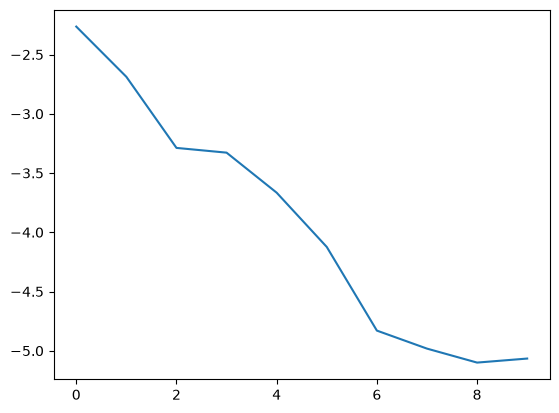

In [27]:
n_layers=3

#Initial Parameters
init_params = 0.01 * np.random.rand(2, n_layers, requires_grad=True)

#Optimizer
opt = qp.AdagradOptimizer(stepsize=0.5)

params = init_params.copy()
steps = 50
callback=[]
for i in range(steps):
    params = opt.step(cost_function, params)
    if (i + 1) % 5 == 0:
        cost=cost_function(params)
        callback.append(cost)
        print(f"Cost {i+1:3d}: {cost: .7f}")

plt.plot(callback)
plt.show()

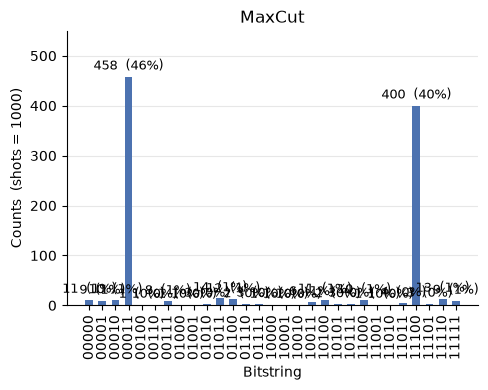

In [28]:
from utils import plot_hist
counts = qaoa_circuit(*params,return_samples=True)
plot_hist(counts,title="MaxCut")

Here we consider the Approximation Ratio as measure: $$AR=\frac{C_{QAOA}}{C_{exact}}$$
but there are many others, like the probability to sample the optimal solution, and so on..

let's write down the classical objective:

In [29]:
def maxcut_obj(G,x):
    cut = 0
    for i, j in G.edges():
        if x[i] != x[j]:
            cut -= 1
    return cut

Each measured bit string $x$ is one possible cut. If $x$ was measured $n_x$ times out of $N_{\text{shots}}$, the expected cut value is estimated by
\begin{equation}
    \langle C\rangle \approx \frac{1}{N_{\text{shots}}}\sum_{x \in \text{counts}} n_x\, C(x),
\end{equation}
where $C(x)$ is given by `maxcut_obj(G, x)`.

In [31]:
counts

{np.str_('00000'): np.int64(11),
 np.str_('00001'): np.int64(9),
 np.str_('00010'): np.int64(10),
 np.str_('00011'): np.int64(458),
 np.str_('00100'): np.int64(1),
 np.str_('00110'): np.int64(1),
 np.str_('00111'): np.int64(8),
 np.str_('01000'): np.int64(1),
 np.str_('01001'): np.int64(1),
 np.str_('01010'): np.int64(3),
 np.str_('01011'): np.int64(14),
 np.str_('01100'): np.int64(12),
 np.str_('01110'): np.int64(2),
 np.str_('01111'): np.int64(3),
 np.str_('10000'): np.int64(1),
 np.str_('10001'): np.int64(1),
 np.str_('10010'): np.int64(1),
 np.str_('10011'): np.int64(6),
 np.str_('10100'): np.int64(11),
 np.str_('10101'): np.int64(2),
 np.str_('10111'): np.int64(3),
 np.str_('11000'): np.int64(10),
 np.str_('11001'): np.int64(1),
 np.str_('11010'): np.int64(1),
 np.str_('11011'): np.int64(4),
 np.str_('11100'): np.int64(400),
 np.str_('11101'): np.int64(3),
 np.str_('11110'): np.int64(13),
 np.str_('11111'): np.int64(9)}

In [30]:
def maxcut_cost_funct(G,counts):
    energy = 0
    for meas, p in counts.items():
        obj_for_meas = maxcut_obj(G,meas)
        energy += obj_for_meas * p
    return energy/N_SHOTS

In [32]:

def maxcut_exact(G, weight="w"):
    n = G.number_of_nodes()
    nodes = {v: k for k, v in enumerate(G.nodes())}
    s = np.arange(2 ** (n - 1), dtype=np.int64)      
    cut = np.zeros(2 ** (n - 1))
    for u, v, d in G.edges(data=True):
        i, j = nodes[u], nodes[v]
        cut += d.get(weight, 1.0) * (((s >> i) ^ (s >> j)) & 1)
    best = int(np.argmax(cut))
    bits = np.array([(best >> k) & 1 for k in range(n)])
    return float(cut[best]), bits

def approximation_ratio(G,counts):
    return  -maxcut_cost_funct(G,counts)/maxcut_exact(G)[0]

def success_probability(G, counts):
    shots = sum(counts.values())
    hits = sum(c for bs, c in counts.items() if -maxcut_obj(G, bs) > maxcut_exact(G)[0] - 1e-9)
    return hits / shots

approximation_ratio(G,counts),success_probability(G,counts)

(np.float64(0.927), np.float64(0.858))

# Barren Plateaus

Classical optimization can be a problem: Barren Plateaus! 

References: https://arxiv.org/abs/2607.00945 showing BP-free for complete graphs, https://arxiv.org/abs/2512.24577: BP for "almost all graphs" and ER falls there.


Def: An Erdős-Rényi random graph $G(n,p)$ has $n$ nodes, where each of the $\binom{n}{2}$ possible edges is included independently with probability $p$. On average it has $p\,n(n-1)/2$ edges, and each node has degree $p\,(n-1)$.

In [33]:

rng = np.random.default_rng(11)

def er(n):                       
    G = nx.gnp_random_graph(n, 0.5, seed=int(rng.integers(1e6)))
    return G

def complete(n):               
    G = nx.complete_graph(n)
    return G


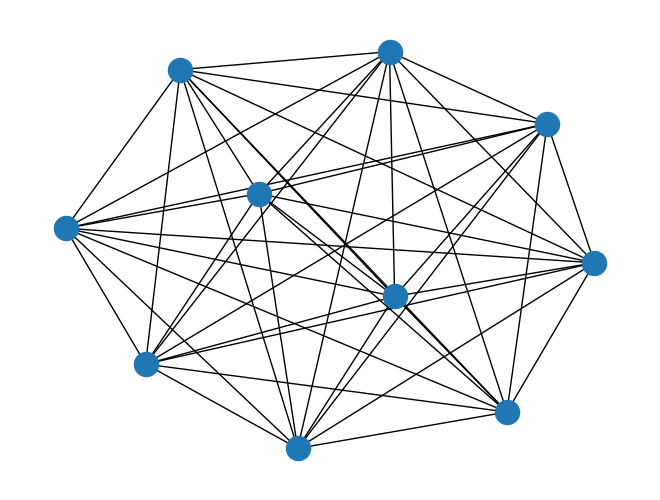

In [35]:
erg=complete(10)
nx.draw(erg)

In [36]:
def maxcut_hamiltonian(G):
    E = list(G.edges())
    m = len(E)
    coeffs = [-0.5] + [0.5 / m] * m
    ops    = [qp.Identity(0)] + [qp.Z(i) @ qp.Z(j) for i, j in E]
    return qp.Hamiltonian(coeffs, ops)

def make_qnode(G, n, p, shots=None, return_samples=False):

    E = list(G.edges())

    H = maxcut_hamiltonian(G)

    dev = qp.device("lightning.qubit", wires=n)

    @qp.qnode(dev, shots=shots,
              diff_method="adjoint" if shots is None else "parameter-shift")
    def circ(params):
        g, b = params[0], params[1]

        for w in range(n):
            qp.Hadamard(w)
        for l in range(p):
            for i, j in E:
                qp.IsingZZ(2 * g[l], wires=[i, j])
            for w in range(n):
                qp.RX(2 * b[l], wires=w)

        if return_samples:
            return qp.counts()
        return qp.expval(H)

    return circ

def grad_var(G, n, p, samples=50):
     grad_vals=[]
     for _ in range(samples):
          qcircuit= make_qnode(G, n, p); 
          grad = qp.grad(qcircuit)
          params=np.array(rng.uniform(0, 2*np.pi, (2, p)))
          gradient = grad(params)
          grad_vals.append(gradient[-1])

     return  np.var(grad_vals)

n_nodes=range(4,14,2)
grad_vars_er=[]
grad_vars_c=[]
for n in n_nodes:
    grad_vars_er.append(grad_var(er(n),n,n))
    grad_vars_c.append(grad_var(complete(n),n,n))

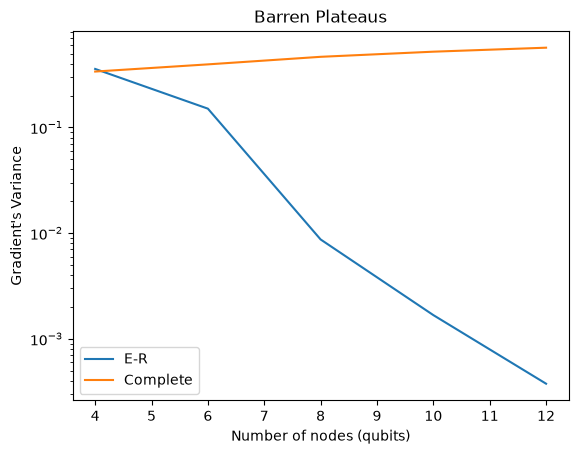

In [37]:
plt.plot(n_nodes,grad_vars_er,label="E-R")
plt.plot(n_nodes,grad_vars_c,label="Complete")
plt.yscale("log")
plt.title("Barren Plateaus")
plt.xlabel("Number of nodes (qubits)")
plt.ylabel("Gradient's Variance")
plt.legend()
plt.show()

### Linear Ramp QAOA

https://arxiv.org/abs/2405.09169 

Instead of optimizing all $2p$ angles independently, LR-QAOA fixes them with a linear schedule controlled by only two parameters, $\Delta_\gamma$ and $\Delta_\beta$:
$$
    \gamma_k = \frac{k}{p}\,\Delta_\gamma, \qquad 
    \beta_k = -\left(1 - \frac{k-1}{p}\right)\Delta_\beta, \qquad k = 1,\dots,p.
$$
Over the layers, $\gamma_k$ grows linearly while $|\beta_k|$ decreases linearly. 
This mimics a Trotterized adiabatic evolution and
for large $p$ and small enough $\Delta_\gamma, \Delta_\beta$, the adiabatic theorem suggests the final state approaches the ground state of the cost Hamiltonian. 
Since the number of parameters does not grow with $p$, LR-QAOA avoids the costly high-dimensional optimization and can also serve as a smart initialization for standard QAOA.

Let's make another example

In [38]:

n_wires=12
G= er(n)
sol=maxcut_exact(G)
sol

(26.0, tensor([1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0], requires_grad=True))

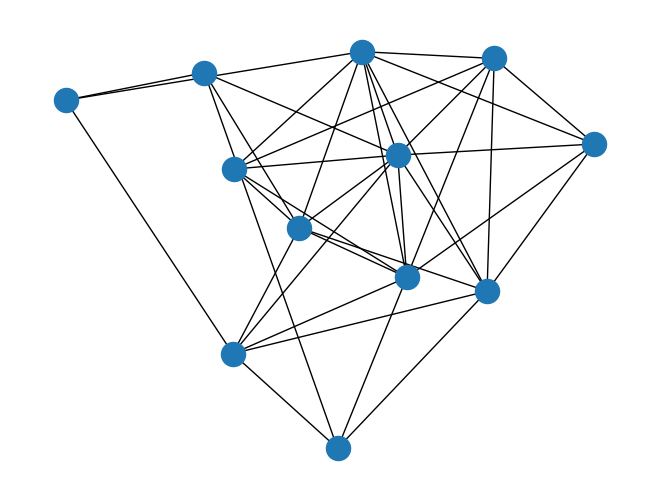

In [39]:
nx.draw(G)

In [40]:
n_layers=5

def cost_function(params):
    qcircuit = make_qnode(G, n_wires, n_layers); 
    return qcircuit(params)

#Initial Parameters
init_params = 0.01 * np.random.rand(2, n_layers, requires_grad=True)
#Optimizer
opt = qp.AdagradOptimizer(stepsize=0.5)

params = init_params.copy()
steps = 50
for i in range(steps):
    params = opt.step(cost_function, params)
    if (i + 1) % 5 == 0:
        print(f"Cost {i+1:3d}: {cost_function(params): .7f}")

qcircuit= make_qnode(G, n_wires, n_layers,shots=N_SHOTS,return_samples=True)
counts = qcircuit(params)
qaoa_sol_ar=approximation_ratio(G,counts)
qaoa_sol_sp=success_probability(G,counts)

Cost   5: -0.5007305
Cost  10: -0.5005892
Cost  15: -0.5053525
Cost  20: -0.5035107
Cost  25: -0.5032170
Cost  30: -0.5034082
Cost  35: -0.5023532
Cost  40: -0.5039149
Cost  45: -0.5030678
Cost  50: -0.5022724


In [41]:
qaoa_sol_sp,qaoa_sol_ar

(np.float64(0.001), np.float64(0.6993461538461538))

In [42]:
def find_LR_params(p,
            delta_beta=.3,
            delta_gamma=.6):
    beta_in = [-(1-i/p)* delta_beta for i in range(p)]
    gamma_in = [((1+i)/p) * delta_gamma for i in range(p)]
    return gamma_in,beta_in

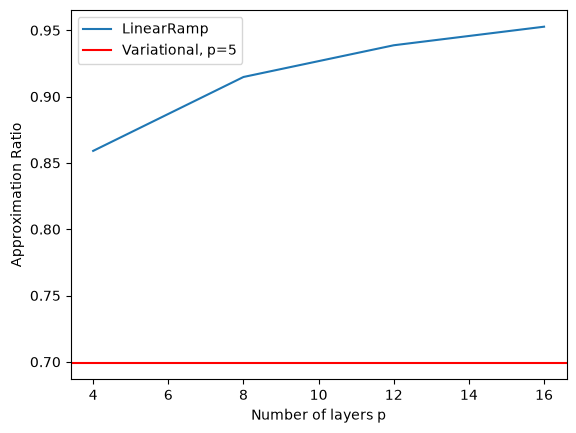

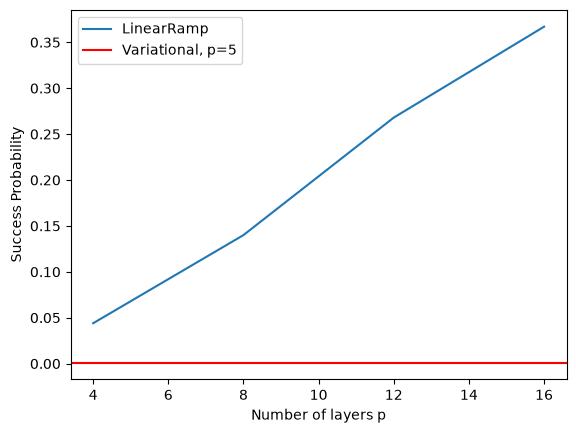

In [43]:
en_ar=[]
en_sp=[]
depths=range(4,20,4)
for p in depths:
    params=find_LR_params(p)
    qcircuit= make_qnode(G, n_wires, p,shots=N_SHOTS,return_samples=True)
    counts = qcircuit(params)
    en_ar.append(approximation_ratio(G,counts))
    en_sp.append(success_probability(G,counts))


plt.plot(depths,en_ar,label="LinearRamp")
plt.axhline(qaoa_sol_ar,color="red",label=f"Variational, p={n_layers}")
plt.xlabel("Number of layers p")
plt.ylabel("Approximation Ratio")
plt.legend()
plt.show()

plt.plot(depths,en_sp,label="LinearRamp")
plt.axhline(qaoa_sol_sp,color="red",label=f"Variational, p={n_layers}")
plt.xlabel("Number of layers p")
plt.ylabel("Success Probability")
plt.legend()
plt.show()

The example above shows a specific clear fail of the variational QAOA due to Barren Plateaus. Nevertheless, we just tried with a naive setting, without exploring different layers, optimizers, cost functions and most importantly initializations of parameters. Smart initialization techniques can avoid flat portions of the landscape and allow to find good parts of the Hilbert space where to start the optimization. Indeed LR-QAOA is actually an example of that!


We encourage to have a look at the resouces required in terms of circuit and on number of measurmenets as well. 
Finally, feel free to join the LR-QAOA with the variational approach: the former can favor a good starting point for the optimization, while the latter could improve a shallower circuit of the former in order to reduce the depth of the circuit required to find the solution!


# Constrained Problems?
We have just observed MaxCut, but interesting problems are featured by constraints.
1) Classical Penalty terms in the cost function. There could be problems tuning and scaling such terms, but some smart methods have been proposed https://arxiv.org/abs/2211.13914
2) Quantum way: change the mixers! Grover mixer https://arxiv.org/abs/2006.00354 (or even problem-specific ones https://arxiv.org/pdf/2406.15228)

# Is QAOA practically useful?
A potential advantage: https://arxiv.org/abs/2308.02342 